In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/rodrigomonteiro2/caboverd/cabo_verde.db


In [5]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print(root)
    for file in files:
        print("   ", file)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/rodrigomonteiro2
/kaggle/input/datasets/rodrigomonteiro2/caboverd
    cabo_verde.db


## Python Analise

Labor market and remittances in Cape Verde

## Connect to the database and load the data.

In [ ]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

conn = sqlite3.connect('/kaggle/input/datasets/rodrigomonteiro2/caboverd/cabo_verde.db')

df = pd.read_sql('''
    SELECT d.ano, i.name AS indicador, d.value
    FROM dados_anuais d
    JOIN indicadores i ON d.indicador_id = i.id;
''', conn)

df.head()

,ano,indicador,value
0,2025,"Personal remittances, received (% of GDP)",11.671706
1,2024,"Personal remittances, received (% of GDP)",12.307536
2,2023,"Personal remittances, received (% of GDP)",12.632262
3,2022,"Personal remittances, received (% of GDP)",14.031084
4,2021,"Personal remittances, received (% of GDP)",15.328085


## Simplify indicator names

Replace long WORLD BANK names with short labels before any analysis.

In [14]:
nomes_curtos = {
    'Unemployment, total (% of total labor force) (modeled ILO estimate)': 'Desemprego (%)',
    'Personal remittances, received (% of GDP)': 'Remessas (% PIB)',
    'Inflation, consumer prices (annual %)': 'Inflação (%)',
    'GDP per capita (current US$)': 'PIB per capita (US$)',
}

df['indicador'] = df['indicador'].replace(nomes_curtos)
df.head()

,ano,indicador,value
0,2025,Remessas (% PIB),11.671706
1,2024,Remessas (% PIB),12.307536
2,2023,Remessas (% PIB),12.632262
3,2022,Remessas (% PIB),14.031084
4,2021,Remessas (% PIB),15.328085


## Explore Data

In [15]:
print(df.describe())
print()
print(df.groupby('indicador')['ano'].agg(['min', 'max', 'count']))

               ano        value
count   169.000000   169.000000
mean   2004.136095   628.092457
std      12.613737  1314.666859
min    1980.000000    -2.477457
25%    1994.000000     8.641463
50%    2004.000000    13.294000
75%    2015.000000   422.664668
max    2025.000000  5796.472079

                       min   max  count
indicador                              
Desemprego (%)        1991  2025     35
Inflação (%)          1984  2025     42
PIB per capita (US$)  1980  2025     46
Remessas (% PIB)      1980  2025     46


## Organizar numa tabela larga (pivot)

uma coluna por indicador, uma linha por ano -- fica mais facil de cruzar e fazer gráficos

In [16]:
pivot = df.pivot(index='ano', columns='indicador', values='value')
pivot.head()

indicador,Desemprego (%),Inflação (%),PIB per capita (US$),Remessas (% PIB)
ano,,,,
1980,NaN,NaN,439.982602,28.165692
1981,NaN,NaN,425.407689,22.655263
1982,NaN,NaN,422.664668,18.382911
1983,NaN,NaN,410.112647,14.838648
1984,NaN,11.25,385.451420,15.617329


## Gráficos: Desemprego vs Remessas (duplo eixo)

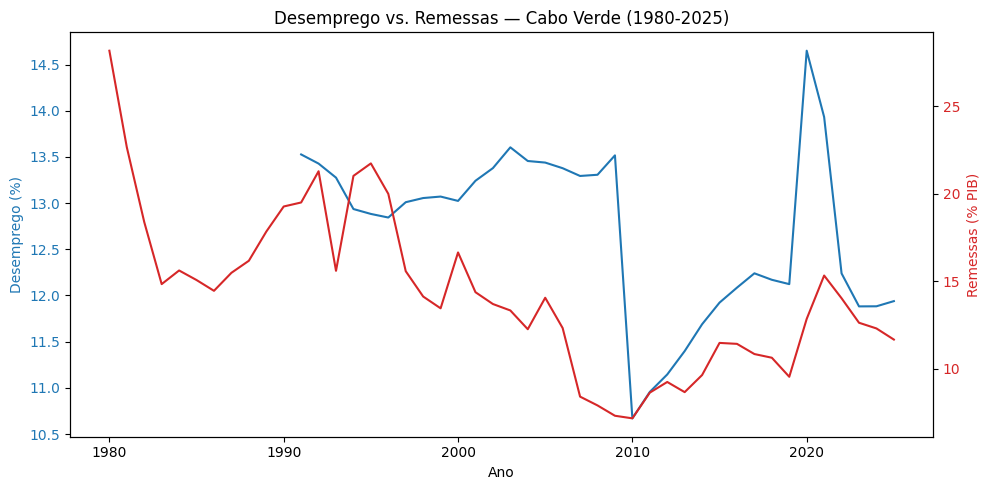

In [17]:
fig, ax1 = plt.subplots(figsize=(10,5))

ax1.plot(pivot.index, pivot['Desemprego (%)'], color = 'tab:blue', label='Desemprego')
ax1.set_xlabel('Ano')
ax1.set_ylabel('Desemprego (%)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.plot(pivot.index, pivot['Remessas (% PIB)'], color='tab:red', label='Remessas')
ax2.set_ylabel('Remessas (% PIB)', color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title('Desemprego vs. Remessas — Cabo Verde (1980-2025)')
fig.tight_layout()
plt.savefig('desemprego_remessas.png', dpi=150)
plt.show()

## Correlação entre os 4 indicadores

Não é causalidade -- só descreve o padrão entre as séries

indicador             Desemprego (%)  Inflação (%)  PIB per capita (US$)  \
indicador                                                                  
Desemprego (%)                  1.00          0.12                 -0.54   
Inflação (%)                    0.12          1.00                 -0.45   
PIB per capita (US$)           -0.54         -0.45                  1.00   
Remessas (% PIB)                0.45          0.43                 -0.71   

indicador             Remessas (% PIB)  
indicador                               
Desemprego (%)                    0.45  
Inflação (%)                      0.43  
PIB per capita (US$)             -0.71  
Remessas (% PIB)                  1.00  


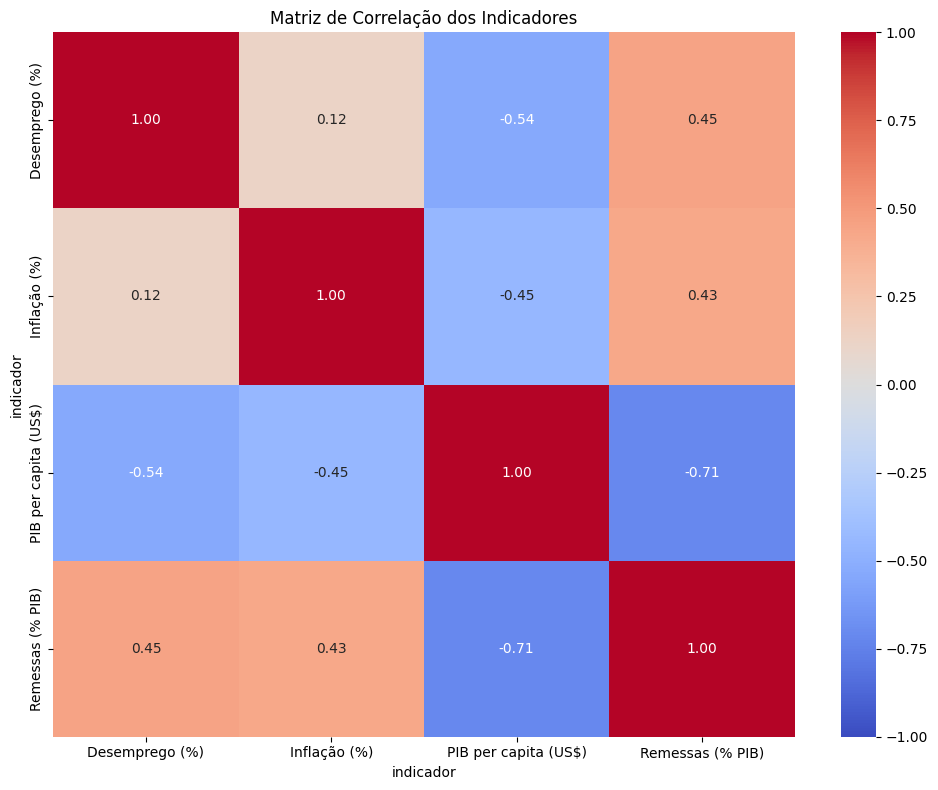

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calcular a matriz de correlação
corr = pivot.corr()

# 2. Arredondar para 2 casas decimais
print(corr.round(2))

# 3. Criar o gráfico
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

# 4. Título
plt.title("Matriz de Correlação dos Indicadores")

# 5. Ajustar o gráfico
plt.tight_layout()

# 6. Mostrar
plt.show()

## Comparar modelos de previsão: ARIMA VS Regressão Linear

Em vez de confiar só num modelo, fazemos um **backtest**: treinamos cada modelo só com dados até 2022 e comparamos a previsão com o que realmente aconteceu em 2023-2025.

In [26]:
import numpy as np
from statsmodels.tsa.arima.model import ARIMA

# 1. Separar treino (até 2022) e teste (2023-2025, já conhecidos)
serie_completa = pivot['Desemprego (%)'].dropna()
ano_corte = 2022
treino = serie_completa[serie_completa.index <= ano_corte]
teste = serie_completa[serie_completa.index > ano_corte]
anos_teste = teste.index.tolist()
valores_reais = teste.values

# 2. Treinar e prever com ARIMA
treino_arima = treino.copy()
treino_arima.index = pd.PeriodIndex(treino.index.astype(int), freq='Y')
modelo_arima = ARIMA(treino_arima, order=(1, 1, 1)).fit()
previsao_arima = modelo_arima.get_forecast(steps=len(anos_teste)).predicted_mean.values

# 3. Treinar e prever com Regressão Linear
X_treino = treino.index.values.reshape(-1, 1)
y_treino = treino.values
modelo_reg = LinearRegression().fit(X_treino, y_treino)
previsao_reg = modelo_reg.predict(np.array(anos_teste).reshape(-1, 1))

In [27]:
# 4. Métricas de erro: MAE, MAPE, Acurácia
def calcular_metricas(reais, previstos, nome_modelo):
    erro_abs = np.abs(reais - previstos)
    mae = np.mean(erro_abs)
    mape = np.mean(erro_abs / np.abs(reais)) * 100
    acuracia = 100 - mape
    print(f"{nome_modelo:<20} MAE: {mae:.3f}   MAPE: {mape:.2f}%   Acurácia: {acuracia:.2f}%")
    return {"modelo": nome_modelo, "mae": mae, "mape": mape, "acuracia": acuracia}

print(f"{'Ano':<6}{'Real':<8}{'ARIMA':<10}{'Reg.Linear':<12}")
for a, r, pa, pr in zip(anos_teste, valores_reais, previsao_arima, previsao_reg):
    print(f"{a:<6}{r:<8.2f}{pa:<10.2f}{pr:<12.2f}")
print()

res_arima = calcular_metricas(valores_reais, previsao_arima, "ARIMA(1,1,1)")
res_reg = calcular_metricas(valores_reais, previsao_reg, "Regressão Linear")

melhor = res_arima if res_arima["mae"] < res_reg["mae"] else res_reg
print(f"\n>> Modelo com menor erro no backtest: {melhor['modelo']} (MAE {melhor['mae']:.3f})")

Ano   Real    ARIMA     Reg.Linear  
2023  11.88   12.41     12.23       
2024  11.88   12.53     12.19       
2025  11.94   12.61     12.16       

ARIMA(1,1,1)         MAE: 0.620   MAPE: 5.21%   Acurácia: 94.79%
Regressão Linear     MAE: 0.293   MAPE: 2.46%   Acurácia: 97.54%

>> Modelo com menor erro no backtest: Regressão Linear (MAE 0.293)


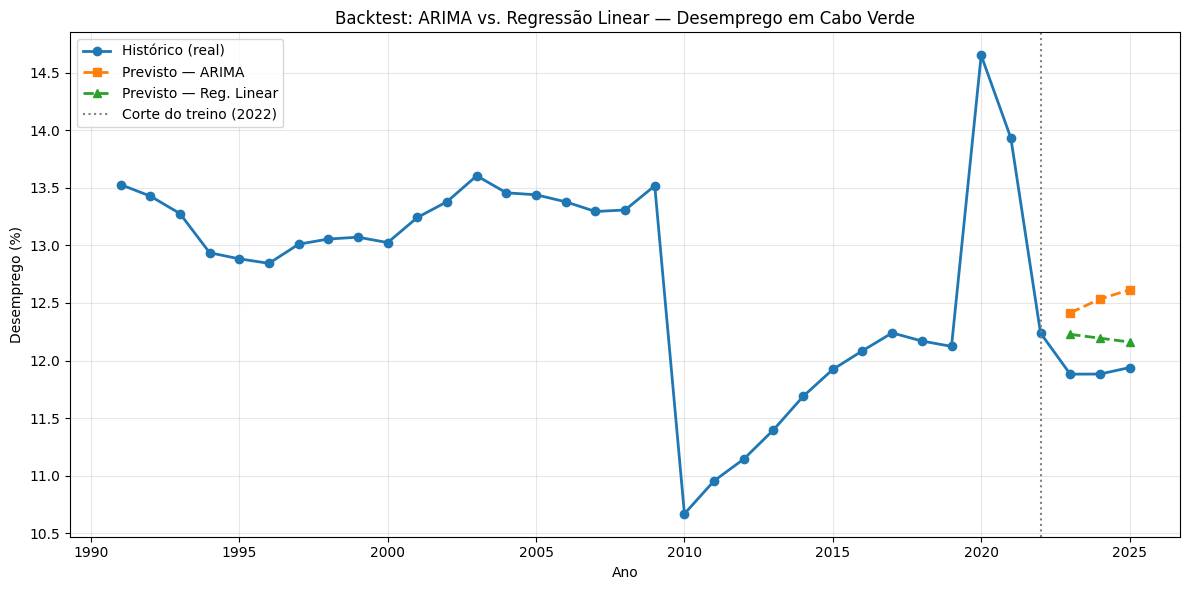

In [28]:
plt.figure(figsize=(12, 6))
plt.plot(serie_completa.index, serie_completa.values, marker='o', linewidth=2, label='Histórico (real)')
plt.plot(anos_teste, previsao_arima, marker='s', linestyle='--', linewidth=2, label='Previsto — ARIMA')
plt.plot(anos_teste, previsao_reg, marker='^', linestyle='--', linewidth=2, label='Previsto — Reg. Linear')
plt.axvline(x=ano_corte, linestyle=':', linewidth=1.5, color='gray', label=f'Corte do treino ({ano_corte})')
plt.title('Backtest: ARIMA vs. Regressão Linear — Desemprego em Cabo Verde')
plt.xlabel('Ano')
plt.ylabel('Desemprego (%)')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('backtest_modelos.png', dpi=150)
plt.show()

In [29]:
# Repete o treino do modelo vencedor, agora com TODOS os dados (1991-2025), para prever o futuro real
X_completo = serie_completa.index.values.reshape(-1, 1)
y_completo = serie_completa.values
modelo_final = LinearRegression().fit(X_completo, y_completo)  # troca para ARIMA se o backtest preferir esse

anos_futuros = [2026, 2027, 2028]
previsao_final = modelo_final.predict(np.array(anos_futuros).reshape(-1, 1))

for ano, valor in zip(anos_futuros, previsao_final):
    print(f"{ano}: {valor:.2f}%")

2026: 12.03%
2027: 12.00%
2028: 11.96%


## Exportar para o Power Bi

In [30]:
pivot_export = pivot.reset_index()
pivot_export.to_csv('cabo_verde_indicadores_limpo.csv', index=False)
print('Ficheiro exportado:', pivot_export.shape)

Ficheiro exportado: (46, 5)
